# Clustering — Significant Earthquakes (1965–2016)
**23CSE301 Machine Learning — Capstone, Review 2 · Group: DATA MINDS**

**Dataset:** `database.csv` — USGS catalogue of significant earthquakes (magnitude ≥ 5.5), 23,412 events × 21 columns.

**Problem statement:** group earthquakes using only their location and depth, with **K-Means** and
**Agglomerative Hierarchical Clustering**, and compare the two using the Silhouette Score, Davies–Bouldin Index and
Calinski–Harabasz Index.

**Notebook flow:** data audit → preprocessing → K-Means (elbow curve) → Agglomerative (dendrogram, linkage
comparison) → evaluation table → PCA / t-SNE / map visualisation → cluster profiles → conclusion.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
RANDOM_STATE = 42          # used for every split, sample and model below
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 80

# Works from notebooks/ (repository layout) or from the repository root
DATA_PATH = "../data/database.csv" if os.path.exists("../data/database.csv") else "data/database.csv"

## 1. Load and audit the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate events (same date, time, latitude, longitude):",
      df.duplicated(subset=["Date", "Time", "Latitude", "Longitude"]).sum())
display(df.head())

audit = pd.DataFrame({"dtype": df.dtypes.astype(str),
                      "missing": df.isna().sum(),
                      "missing_%": (df.isna().mean() * 100).round(1)})
display(audit.sort_values("missing", ascending=False))
display(df["Type"].value_counts().to_frame("events"))

Shape: (23412, 21)
Fully duplicated rows: 0
Duplicate events (same date, time, latitude, longitude): 0


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


,dtype,missing,missing_%
Magnitude Error,float64,23085,98.6
Horizontal Error,float64,22256,95.1
Horizontal Distance,float64,21808,93.1
Magnitude Seismic Stations,float64,20848,89.0
Depth Error,float64,18951,80.9
Depth Seismic Stations,float64,16315,69.7
Azimuthal Gap,float64,16113,68.8
Root Mean Square,float64,6060,25.9
Magnitude Type,str,3,0.0
Date,str,0,0.0


,events
Type,
Earthquake,23232
Nuclear Explosion,175
Explosion,4
Rock Burst,1


**Observation:** there are no duplicate rows or duplicate events. Latitude, Longitude, Depth and Magnitude have no
missing values. The measurement-error and station columns are 26–99 % empty and are not used, so no imputation is
needed. Besides earthquakes, the file contains 175 nuclear explosions, 4 explosions and 1 rock burst.

## 2. Preprocessing and feature engineering
**Ground-truth labels:** the dataset has no cluster labels. The `Type` column is used only to restrict the data to
natural earthquakes before clustering (human-made explosions are a different kind of event); it is not used as a
feature or to fit, select or score any model.

Steps:
1. Keep only `Type == "Earthquake"`.
2. Clip the few slightly negative depths (events reported just above sea level) to 0.
3. Check outliers in depth.
4. Engineer features:
   * **Latitude/longitude → 3-D coordinates** `x, y, z` on a unit sphere, so that points on either side of the
     ±180° longitude line are close in feature space (in raw degrees they would be ~360 apart).
   * **`log_depth = log(1 + depth)`** to reduce the right skew of depth.
5. Magnitude is not used as a feature; it is used only to describe the clusters afterwards.

In [3]:
quakes = df[df["Type"] == "Earthquake"].copy()
print("Negative depths clipped to 0:", (quakes["Depth"] < 0).sum())
quakes["Depth"] = quakes["Depth"].clip(lower=0)

# Outlier check on depth with the 1.5 x IQR rule
q1, q3 = quakes["Depth"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Depth IQR upper fence: {upper:.1f} km -> {(quakes['Depth'] > upper).sum()} events above it "
      f"({(quakes['Depth'] > upper).mean() * 100:.1f} %), max depth = {quakes['Depth'].max():.1f} km")

Negative depths clipped to 0: 3
Depth IQR upper fence: 114.5 km -> 3239 events above it (13.9 %), max depth = 700.0 km


**Outlier decision:** about 14 % of events (3,239) lie above the IQR fence of 114.5 km, and all depths are within the physically possible
range (0–700 km). These are not recording errors, so they are **kept**; the log transform below reduces their influence
instead of deleting them.

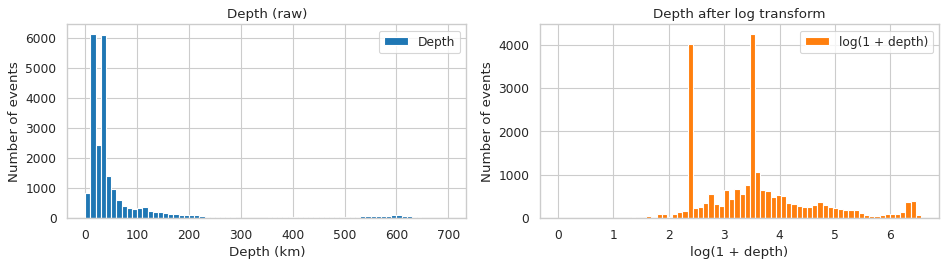

Earthquakes used: 23232
Skewness: depth = 3.28, log_depth = 0.83


,x,y,z,log_depth
count,23232.000,23232.000,23232.000,23232.000
mean,-0.403,0.171,0.019,3.584
std,0.503,0.580,0.468,1.048
min,-0.997,-1.000,-0.975,0.000
25%,-0.849,-0.113,-0.321,2.773
50%,-0.582,0.255,-0.064,3.526
75%,-0.062,0.662,0.422,4.022
max,0.996,1.000,0.998,6.553


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(quakes["Depth"], bins=70, color="tab:blue", label="Depth")
axes[0].set_title("Depth (raw)"); axes[0].set_xlabel("Depth (km)"); axes[0].set_ylabel("Number of events")
axes[0].legend()

lat, lon = np.radians(quakes["Latitude"]), np.radians(quakes["Longitude"])
quakes["x"] = np.cos(lat) * np.cos(lon)
quakes["y"] = np.cos(lat) * np.sin(lon)
quakes["z"] = np.sin(lat)
quakes["log_depth"] = np.log1p(quakes["Depth"])

axes[1].hist(quakes["log_depth"], bins=70, color="tab:orange", label="log(1 + depth)")
axes[1].set_title("Depth after log transform"); axes[1].set_xlabel("log(1 + depth)"); axes[1].set_ylabel("Number of events")
axes[1].legend()
plt.tight_layout(); plt.show()

FEATURES = ["x", "y", "z", "log_depth"]
print("Earthquakes used:", len(quakes))
print("Skewness: depth = %.2f, log_depth = %.2f" % (quakes["Depth"].skew(), quakes["log_depth"].skew()))
display(quakes[FEATURES].describe().round(3))

### 2.1 Train/test split and scaling
* 80:20 split with `random_state=42`. There are no categorical features, so no encoding is needed.
* `StandardScaler` is **fitted on the training set only**, then applied to both sets (no leakage).
* Both models are learned on the training set; the test set is only assigned to the learned clusters, to check that
  the cluster structure holds on unseen events.

In [5]:
train_df, test_df = train_test_split(quakes, test_size=0.2, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(train_df[FEATURES])      # fit on train only
X_train = scaler.transform(train_df[FEATURES])
X_test = scaler.transform(test_df[FEATURES])
print("Train:", X_train.shape, "| Test:", X_test.shape)


def cluster_metrics(X, labels):
    """The three required internal metrics, computed on all points given (no sub-sampling)."""
    return {"Silhouette (↑)": silhouette_score(X, labels),
            "Davies-Bouldin (↓)": davies_bouldin_score(X, labels),
            "Calinski-Harabasz (↑)": calinski_harabasz_score(X, labels)}


def plot_clusters(ax, x, y, labels, title, xlabel, ylabel, s=4):
    """Scatter plot coloured by cluster label, with a legend."""
    sc = ax.scatter(x, y, c=labels, cmap="tab10", s=s, alpha=0.7)
    ax.legend(*sc.legend_elements(), title="Cluster", fontsize=8, loc="best", ncol=2)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

Train: (18585, 4) | Test: (4647, 4)


## 3. K-Means
### 3.1 Elbow curve and metric scan over k

In [6]:
rows = []
for k in range(2, 16):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    rows.append({"k": k, "Inertia": km.inertia_, **cluster_metrics(X_train, km.labels_)})
k_scan = pd.DataFrame(rows).set_index("k")
display(k_scan.round(3))

print("Highest Silhouette:          k =", k_scan["Silhouette (↑)"].idxmax())
print("Lowest Davies-Bouldin:       k =", k_scan["Davies-Bouldin (↓)"].idxmin())
print("Highest Calinski-Harabasz:   k =", k_scan["Calinski-Harabasz (↑)"].idxmax())

,Inertia,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
k,,,,
2,51774.648,0.364,1.316,8099.260
3,39637.699,0.312,1.235,8134.197
4,32262.937,0.321,1.116,8077.736
5,27608.973,0.346,1.070,7862.228
6,23735.418,0.342,0.974,7922.241
7,20737.437,0.350,1.003,8003.524
8,18455.737,0.355,0.962,8035.990
9,16775.398,0.363,0.954,7967.931
10,15466.030,0.358,0.970,7856.535


Highest Silhouette:          k = 2
Lowest Davies-Bouldin:       k = 9
Highest Calinski-Harabasz:   k = 3


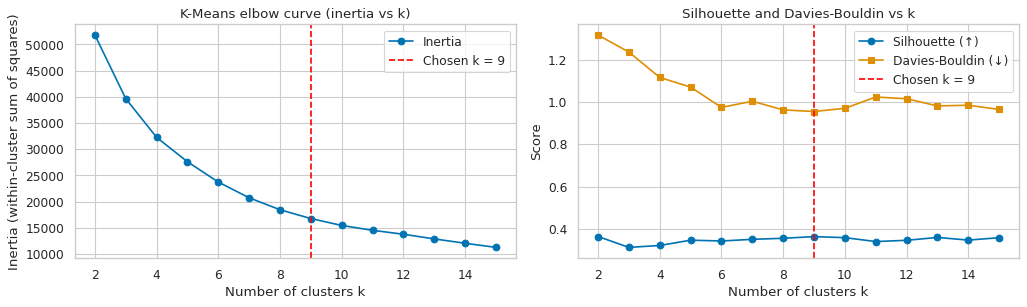

In [7]:
CHOSEN_K = 9

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_scan.index, k_scan["Inertia"], "o-", label="Inertia")
axes[0].axvline(CHOSEN_K, color="red", ls="--", label=f"Chosen k = {CHOSEN_K}")
axes[0].set_title("K-Means elbow curve (inertia vs k)")
axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].legend()

axes[1].plot(k_scan.index, k_scan["Silhouette (↑)"], "o-", label="Silhouette (↑)")
axes[1].plot(k_scan.index, k_scan["Davies-Bouldin (↓)"], "s-", label="Davies-Bouldin (↓)")
axes[1].axvline(CHOSEN_K, color="red", ls="--", label=f"Chosen k = {CHOSEN_K}")
axes[1].set_title("Silhouette and Davies-Bouldin vs k")
axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Score"); axes[1].legend()
plt.tight_layout(); plt.show()

**Choice of k (based on the table above):**
* The elbow curve has **no sharp elbow**; the drop in inertia slows down gradually from about k = 5 onward, so the
  elbow alone does not fix k.
* The **highest Silhouette is at k = 2** (0.364). k = 2 only splits the data into two very broad groups, so it is
  not useful for this problem.
* Among k ≥ 3, the highest Silhouette is at **k = 9 (0.363)**; the next best are k = 13 (0.359) and k = 10 / 15 (0.358).
* **Davies–Bouldin is lowest at k = 9** (0.954) over the whole range.
* Calinski–Harabasz is highest at k = 3 (8,134), stays within about 3.5 % of that up to k = 10, and then falls, so it
  does not single out one k.

**k = 9 is chosen** because it has the lowest Davies–Bouldin Index and the highest Silhouette for k ≥ 3, with
Calinski–Harabasz still close to its maximum. This is a judgement combining several metrics, not a single "best" score.

### 3.2 Final K-Means model

In [8]:
kmeans = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=RANDOM_STATE).fit(X_train)
km_train = kmeans.labels_               # labels of the fitted (training) points
km_test = kmeans.predict(X_test)        # test points assigned to the nearest learned centroid
print("Cluster sizes (train):", np.bincount(km_train))
print("Cluster sizes (test): ", np.bincount(km_test))

Cluster sizes (train): [3922 3340 1193 1544 1454 1317 1595 1353 2867]
Cluster sizes (test):  [1029  797  281  391  389  315  405  310  730]


## 4. Agglomerative Hierarchical Clustering
### 4.1 Why a sample, and how unseen points get labels
Agglomerative clustering needs all pairwise distances, which grows with n². `AgglomerativeClustering` also has
**no `predict` method**, so it cannot label new points by itself. The approach used here is:
1. Fit Agglomerative clustering on a **reproducible random sample of 6,000 training points** (`random_state=42`).
2. Train a **KNN classifier (k = 15)** on the sample and its cluster labels.
3. Use KNN to assign the remaining training points and all test points. This is an **approximation** of the
   hierarchical clustering, not a hierarchical fit of the full data.

In [9]:
n_train = len(X_train)
print(f"Pairwise distances for all {n_train} training points: "
      f"{n_train * (n_train - 1) / 2 * 8 / 1e9:.2f} GB (float64, condensed)")
print(f"Pairwise distances for a 6,000-point sample: {6000 * 5999 / 2 * 8 / 1e9:.2f} GB")

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(n_train, size=6000, replace=False)   # same sample every run
X_sample = X_train[sample_idx]

Pairwise distances for all 18585 training points: 1.38 GB (float64, condensed)
Pairwise distances for a 6,000-point sample: 0.14 GB


### 4.2 Dendrogram (Ward linkage, 6,000-point sample)

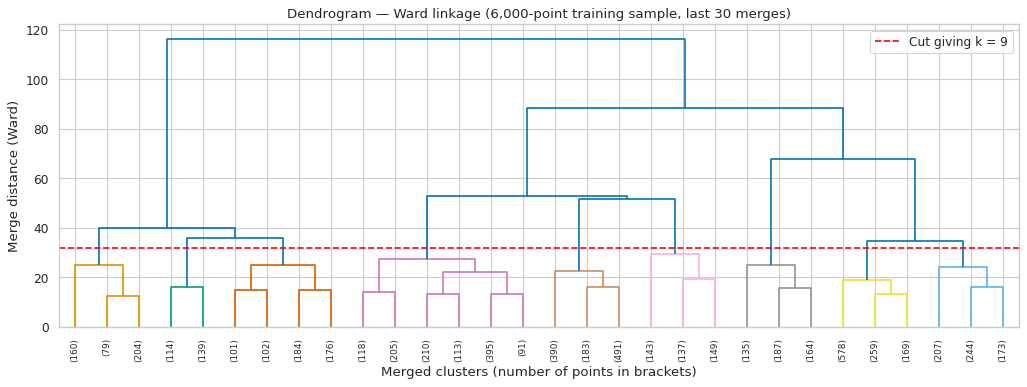

,merge height (k -> k-1),gap below (k+1 -> k vs k -> k-1)
k,,
2,116.41,27.93
3,88.48,20.49
4,67.99,15.23
5,52.76,1.18
6,51.59,11.50
7,40.09,4.32
8,35.77,1.04
9,34.73,5.32
10,29.40,1.93


In [10]:
Z = linkage(X_sample, method="ward")
cut = (Z[-CHOSEN_K, 2] + Z[-CHOSEN_K + 1, 2]) / 2   # any height in this band gives exactly CHOSEN_K clusters

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut, leaf_rotation=90, leaf_font_size=8)
plt.axhline(cut, color="red", ls="--", label=f"Cut giving k = {CHOSEN_K}")
plt.title("Dendrogram — Ward linkage (6,000-point training sample, last 30 merges)")
plt.xlabel("Merged clusters (number of points in brackets)"); plt.ylabel("Merge distance (Ward)")
plt.legend(); plt.tight_layout(); plt.show()

# Height of the merge that reduces k clusters to k-1, and the gap to the next merge
heights = Z[::-1, 2]                       # heights[0] = last merge (2 -> 1 cluster)
gap_table = pd.DataFrame({"k": range(2, 13),
                          "merge height (k -> k-1)": heights[0:11],
                          "gap below (k+1 -> k vs k -> k-1)": heights[0:11] - heights[1:12]}).set_index("k")
display(gap_table.round(2))

**How the cut is chosen:** cutting the tree with a horizontal line gives one cluster per branch crossed. The largest
gaps between merge heights are at small k (2, 3, 4, then 6), so the dendrogram on its own would favour a few large
groups. Between k = 7 and k = 12 the largest gap is at k = 9 (5.32), which is consistent with, but weaker evidence
than, the gaps at small k. The cut is placed at **k = 9 to match the K-Means choice** from Section 3, so that both algorithms can be
compared with the same number of clusters. The dendrogram does **not** by itself prove that 9 is the correct number.

### 4.3 Comparing linkage strategies (on the 6,000-point sample)

In [11]:
linkage_rows = []
for method in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage=method).fit_predict(X_sample)
    linkage_rows.append({"Linkage": method, **cluster_metrics(X_sample, labels),
                         "Largest cluster %": round(np.bincount(labels).max() / len(labels) * 100, 1)})
linkage_table = pd.DataFrame(linkage_rows).set_index("Linkage")
display(linkage_table.round(3))

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Largest cluster %
Linkage,,,,
ward,0.302,1.105,2158.218,18.9
complete,0.238,1.163,1547.689,31.4
average,0.239,1.022,1116.847,57.5
single,-0.100,0.688,3.342,99.8


**Observation:** Ward has the highest Silhouette and Calinski–Harabasz and the most balanced clusters (largest cluster
≈ 19 %). Average and single linkage give a lower Davies–Bouldin, but they put 57 % and 99.8 % of the points into one
cluster (single linkage "chains" neighbouring points together), so that low value comes from very unbalanced
clusters rather than better clustering. **Ward** is selected.

### 4.4 Final Agglomerative model and KNN assignment

In [12]:
agglo = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage="ward").fit(X_sample)
ag_sample = agglo.labels_                           # true hierarchical labels (sample only)

knn = KNeighborsClassifier(n_neighbors=15)
knn_cv = cross_val_score(knn, X_sample, ag_sample, cv=5)
print(f"KNN 5-fold CV accuracy at reproducing the hierarchical labels on the sample: "
      f"{knn_cv.mean():.3f} ± {knn_cv.std():.3f}")
knn.fit(X_sample, ag_sample)

ag_train = knn.predict(X_train)                     # KNN labels for training points outside the sample
ag_train[sample_idx] = ag_sample                    # keep the true hierarchical labels for sampled points
ag_test = knn.predict(X_test)                       # KNN labels for the test set
print("Cluster sizes (train):", np.bincount(ag_train))
print("Cluster sizes (test): ", np.bincount(ag_test))

KNN 5-fold CV accuracy at reproducing the hierarchical labels on the sample: 0.986 ± 0.003
Cluster sizes (train): [1346 3604 1302 1534 1828 3327 1784  788 3072]
Cluster sizes (test):  [328 893 338 372 463 834 450 170 799]


## 5. Evaluation
All three metrics are computed on all points of each set (no sub-sampling). The **label source** column shows where
each label comes from. The first two rows compare the two algorithms like-for-like on the same 6,000 points.

In [13]:
eval_sets = [
    ("K-Means",            "HC sample (6,000)",  "fitted (K-Means on train)",               X_sample, km_train[sample_idx]),
    ("Agglomerative Ward", "HC sample (6,000)",  "hierarchical fit",                       X_sample, ag_sample),
    ("K-Means",            "train (18,585)",     "fitted",                                 X_train,  km_train),
    ("Agglomerative Ward", "train (18,585)",     "6,000 hierarchical + 12,585 KNN-assigned", X_train,  ag_train),
    ("K-Means",            "test (4,647)",       "predict (nearest centroid)",             X_test,   km_test),
    ("Agglomerative Ward", "test (4,647)",       "KNN-assigned",                           X_test,   ag_test),
]
results = pd.DataFrame([{"Algorithm": a, "Data": d, "Label source": src, "n": len(X), **cluster_metrics(X, y)}
                        for a, d, src, X, y in eval_sets])
display(results.round(3))

,Algorithm,Data,Label source,n,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
0,K-Means,"HC sample (6,000)",fitted (K-Means on train),6000,0.360,0.962,2563.001
1,Agglomerative Ward,"HC sample (6,000)",hierarchical fit,6000,0.302,1.105,2158.218
2,K-Means,"train (18,585)",fitted,18585,0.363,0.954,7967.931
3,Agglomerative Ward,"train (18,585)","6,000 hierarchical + 12,585 KNN-assigned",18585,0.301,1.108,6561.465
4,K-Means,"test (4,647)",predict (nearest centroid),4647,0.359,0.962,1971.892
5,Agglomerative Ward,"test (4,647)",KNN-assigned,4647,0.298,1.112,1631.217


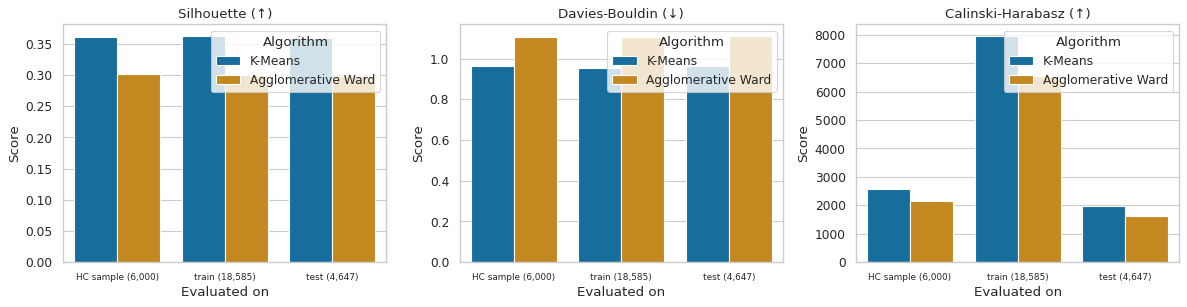

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]):
    sns.barplot(data=results, x="Data", y=metric, hue="Algorithm", ax=ax)
    ax.set_title(metric); ax.set_xlabel("Evaluated on"); ax.set_ylabel("Score")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Observation:** K-Means is better than Agglomerative (Ward) on all three metrics in every row: on the shared
6,000-point sample, on the full training set and on the test set. For each algorithm, Silhouette and Davies–Bouldin
are very similar between train and test, so the clusters hold on unseen events.

**Why Calinski–Harabasz is smaller on the test set.** The index is

CH = [ tr(B) / (k − 1) ] / [ tr(W) / (n − k) ] = ( tr(B) / tr(W) ) × (n − k) / (k − 1),

where tr(B) is the between-cluster dispersion and tr(W) the within-cluster dispersion. The cell below separates the
two parts: if the dispersion ratio tr(B)/tr(W) is about the same on train and test, the difference in CH comes from
the factor (n − k) / (k − 1), because the test set has about a quarter as many points.

In [15]:
ch_parts = results[["Algorithm", "Data", "n", "Calinski-Harabasz (↑)"]].copy()
ch_parts["(n-k)/(k-1)"] = (ch_parts["n"] - CHOSEN_K) / (CHOSEN_K - 1)
ch_parts["tr(B)/tr(W) = CH / factor"] = ch_parts["Calinski-Harabasz (↑)"] / ch_parts["(n-k)/(k-1)"]
display(ch_parts.round(3))

,Algorithm,Data,n,Calinski-Harabasz (↑),(n-k)/(k-1),tr(B)/tr(W) = CH / factor
0,K-Means,"HC sample (6,000)",6000,2563.001,748.875,3.422
1,Agglomerative Ward,"HC sample (6,000)",6000,2158.218,748.875,2.882
2,K-Means,"train (18,585)",18585,7967.931,2322.000,3.431
3,Agglomerative Ward,"train (18,585)",18585,6561.465,2322.000,2.826
4,K-Means,"test (4,647)",4647,1971.892,579.750,3.401
5,Agglomerative Ward,"test (4,647)",4647,1631.217,579.750,2.814


**Observation:** the dispersion ratio tr(B)/tr(W) is almost the same on train and test for each algorithm; the gap in
CH is explained by the (n − k)/(k − 1) factor. CH should therefore only be compared between algorithms on the same
data, not between data sets of different sizes.

## 6. Cluster visualisation
### 6.1 PCA (2 principal components, fitted on the scaled training data)

Explained variance: PC1 = 36.2 %, PC2 = 28.5 %, total = 64.7 %


,PC1,PC2
Loading,,
x,0.626,0.290
y,-0.620,0.329
z,-0.259,0.726
log_depth,-0.397,-0.529


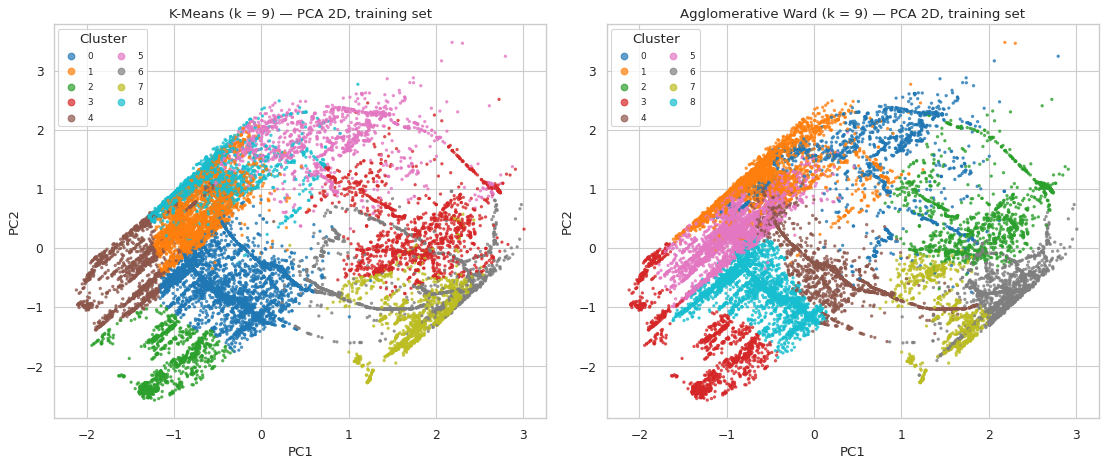

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train)
P = pca.transform(X_train)
print("Explained variance: PC1 = %.1f %%, PC2 = %.1f %%, total = %.1f %%"
      % (*(pca.explained_variance_ratio_ * 100), pca.explained_variance_ratio_.sum() * 100))
display(pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(3).rename_axis("Loading"))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_clusters(axes[0], P[:, 0], P[:, 1], km_train, "K-Means (k = 9) — PCA 2D, training set", "PC1", "PC2")
plot_clusters(axes[1], P[:, 0], P[:, 1], ag_train, "Agglomerative Ward (k = 9) — PCA 2D, training set", "PC1", "PC2")
plt.tight_layout(); plt.show()

**Observation:** the two components keep about 65 % of the variance (the loadings table shows which features
drive each component), so 2D overlap between clusters is expected and does not by itself mean the clusters overlap
in the 4-D feature space. Cluster numbers are arbitrary, so the same colour does not mean the same group in the two
plots.

### 6.2 t-SNE (3,000-point training sample)

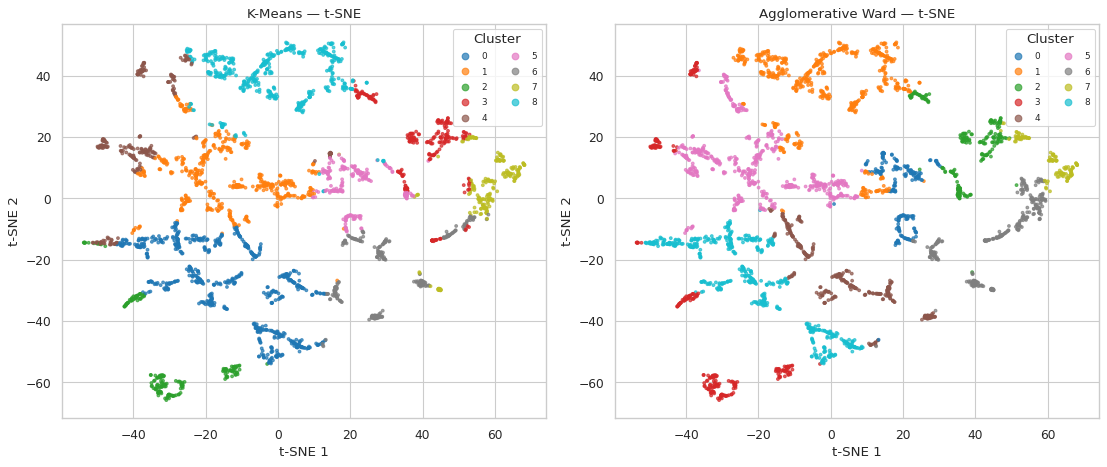

In [17]:
tsne_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train), size=3000, replace=False)
T = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X_train[tsne_idx])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_clusters(axes[0], T[:, 0], T[:, 1], km_train[tsne_idx], "K-Means — t-SNE", "t-SNE 1", "t-SNE 2", s=6)
plot_clusters(axes[1], T[:, 0], T[:, 1], ag_train[tsne_idx], "Agglomerative Ward — t-SNE", "t-SNE 1", "t-SNE 2", s=6)
plt.tight_layout(); plt.show()

**Observation:** t-SNE preserves local neighbourhoods, not global distances, so it shows whether points of the same
cluster stay together; distances between groups on the plot should not be interpreted.

### 6.3 Clusters on the world map (training set)

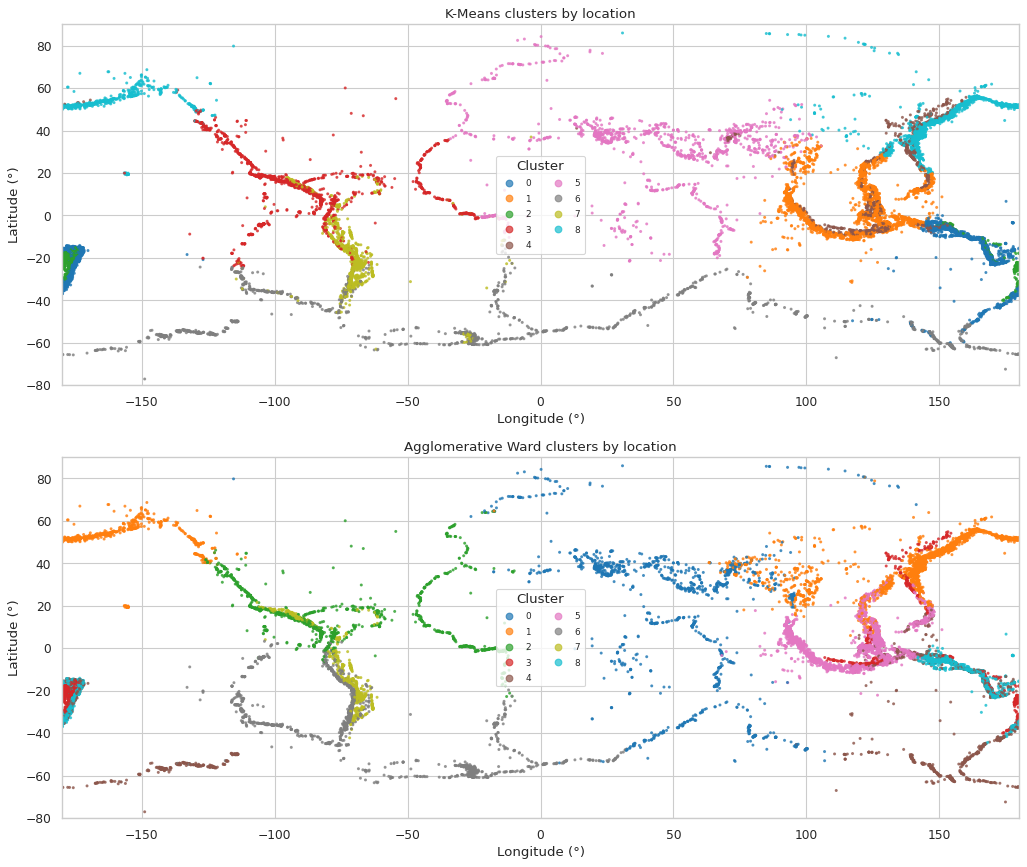

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(13, 11))
plot_clusters(axes[0], train_df["Longitude"], train_df["Latitude"], km_train,
              "K-Means clusters by location", "Longitude (°)", "Latitude (°)", s=3)
plot_clusters(axes[1], train_df["Longitude"], train_df["Latitude"], ag_train,
              "Agglomerative Ward clusters by location", "Longitude (°)", "Latitude (°)", s=3)
for ax in axes:
    ax.set_xlim(-180, 180); ax.set_ylim(-80, 90)
plt.tight_layout(); plt.show()

**Observation (from the plot):** each cluster occupies a connected geographic area, and points just east and west of
the ±180° line fall in the same cluster, as intended by the 3-D coordinates.

> ✍️ **Team interpretation (to be written by the team):** compare these regions with a tectonic plate map and
> describe which regions match. Treat this as a comparison, not as proof of geological causes.

## 7. Cluster profiles (K-Means, described after fitting)

In [19]:
profile = train_df.assign(Cluster=km_train).groupby("Cluster").agg(
    events=("Depth", "size"),
    median_lat=("Latitude", "median"),
    median_lon=("Longitude", "median"),
    median_depth_km=("Depth", "median"),
    pct_deeper_than_300km=("Depth", lambda s: (s > 300).mean() * 100),
    mean_magnitude=("Magnitude", "mean"),
    max_magnitude=("Magnitude", "max"),
)
display(profile.round(2))

,events,median_lat,median_lon,median_depth_km,pct_deeper_than_300km,mean_magnitude,max_magnitude
Cluster,,,,,,,
0,3922,-15.48,152.72,33.00,0.00,5.89,8.1
1,3340,2.26,123.72,33.00,0.00,5.88,8.6
2,1193,-19.88,-175.83,362.70,52.72,5.88,7.8
3,1544,13.29,-89.12,12.00,0.00,5.89,8.0
4,1454,5.16,128.58,151.55,24.69,5.89,8.3
5,1317,35.30,46.62,11.90,0.00,5.88,7.9
6,1595,-53.27,-26.26,10.00,0.00,5.84,8.2
7,1353,-23.01,-70.94,80.00,5.91,5.91,8.8
8,2867,44.88,142.46,33.00,0.00,5.89,9.1


**Observation (from the table):** six of the nine clusters have a median depth of 10–33 km and one has 80 km. Two clusters stand out by depth:
one with a median of about 360 km (over half of its events deeper than 300 km) and one with a median of about
150 km. Mean magnitude differs by less than 0.1 between clusters.

> ✍️ **Team interpretation (to be written by the team):** what the deep clusters and the regional clusters may
> correspond to, and whether leaving magnitude out of the features was a reasonable choice.

## 8. Conclusion

In [20]:
summary = results[results["Data"].str.startswith("test")].set_index("Algorithm")[
    ["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]]
display(summary.round(3))

,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
Algorithm,,,
K-Means,0.359,0.962,1971.892
Agglomerative Ward,0.298,1.112,1631.217


**Final model: K-Means (k = 9).** It is better than Agglomerative Ward on all three metrics, on the shared sample, the
training set and the test set; its train and test scores are close; and it can label new events directly with
`predict`. Agglomerative clustering with Ward linkage was the best of the four linkages and gives a useful dendrogram,
but on this dataset it had to be fitted on a 6,000-point sample with KNN assignment for the rest.

**Limitations**
* k = 9 is a judgement across metrics: Silhouette is highest at k = 2, and Calinski–Harabasz at k = 3.
* Agglomerative results on the full train and test sets rely on the KNN approximation (CV accuracy reported in 4.4).
* The catalogue only contains magnitude ≥ 5.5 events, and aftershocks make events non-independent.
* K-Means favours compact, roughly spherical clusters.

> ✍️ **Team conclusion (to be written by the team):** what the clustering tells you about this dataset.